
<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 15px; height: 80px">

# Random Forests and ExtraTrees


_Authors: Matt Brems (DC), Riley Dallas (AUS)_

---

## Random Forests

The Random Forest is one of the most powerful machine learning algorithms available today. It is a supervised machine learning algorithm that can be used for both classification and regression.

With bagged decision trees, we generate many different trees on pretty similar data. These trees are **highly correlated** with one another. 

If two trees are highly correlated, then the variance will be about as high as we'd see with individual decision trees. 

By de-correlating our trees from one another, we can drastically reduce the variance of our model.

This change will reduce our variance (at the expense of a small increase in bias). This should often improve our model's performance.

So how do we de-correlate our trees?

![](../assets/images/forest.jpeg)

Random forests differ from bagging decision trees in only one way: they use a modified tree learning algorithm that selects, at each split in the learning process, a **random subset of the features**. This process is sometimes called the *random subspace method*. This way the trees built with the training data can be quite different from each other.

The reason for doing this is the correlation of the trees in an ordinary bootstrap sample: if one or a few features are very strong predictors for the response variable (target output), these features will be used in many/all of the bagged decision trees, causing them to become correlated. By selecting a random subset of features at each split, we counter this correlation between base trees, strengthening the overall model.


For a problem with $p$ features, it is typical to use:

- $\sqrt{p}$ (rounded down) features in each split for a classification problem.
- $p/3$ (rounded down) with a minimum node size of 5 as the default for a regression problem.

While this is a guideline, Hastie and Tibshirani (authors of Introduction to Statistical Learning and Elements of Statistical Learning) have suggested this as a good rule in the absence of some rationale to do something different.

Random forests, a step beyond bagged decision trees, are **very widely used** classifiers and regressors. They are relatively simple to use because they require very few parameters to set and they perform pretty well.
- It is quite common for interviewers to ask how a random forest is constructed or how it is superior to a single decision tree.

--- 

## Picture Worth A Thousand Words

![image](https://miro.medium.com/max/720/1*5vlUF8FRR6flPPWK4wt-Kw.png)

[Source](https://medium.com/@harshdeepsingh_35448/understanding-random-forests-aa0ccecdbbbb)

## Extremely Randomized Trees (ExtraTrees) 🌲🌴🌳
Adding another step of randomization (and thus de-correlation) yields extremely randomized trees, or _ExtraTrees_. Like Random Forests, these are trained using the random subspace method (sampling of features). However, they are trained on the entire dataset instead of bootstrapped samples. A layer of randomness is introduced in the way the nodes are split. Instead of computing the locally optimal feature/split combination (based on, e.g., information gain or the Gini impurity) for each feature under consideration, a random value is selected for the split. This value is selected from the feature's empirical range.

This further reduces the variance, but causes an increase in bias. If you're considering using ExtraTrees, you might consider this to be a hyperparameter you can tune. Build an ExtraTrees model and a Random Forest model, then compare their performance!

That's exactly what we'll do below.

## Import libraries
---

We'll need the following libraries for today's lecture:
- `pandas`
- `numpy`
- `GridSearchCV`, `train_test_split` and `cross_val_score` from `sklearn`'s `model_selection` module 
- `RandomForestClassifier` and `ExtraTreesClassifier` from `sklearn`'s `ensemble` module 

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import cross_val_score, train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer

## Load Data
---

Load `train.csv` and `test.csv` from Kaggle into `DataFrames`.

In [58]:
train = pd.read_csv('../datasets/train.csv')
test = pd.read_csv('../datasets/test.csv')

In [59]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [60]:
train.shape

(891, 12)

In [61]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [62]:
test.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

## Data Cleaning: Drop the two rows with missing `Embarked` values from train
---

In [63]:
train[train['Embarked'].isnull()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
61,62,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN
829,830,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN


In [64]:
train = train[train['Embarked'].notnull()]

In [65]:
train.shape

(889, 12)

## Data Cleaning: `Fare`
---

The test set has one row with a missing value for `Fare`. Fill it with the average `Fare` with everyone from the same `Pclass`. **Use the training set to calculate the average!**

In [66]:
mean_fare_3 = train[train['Pclass'] == 3]['Fare'].mean()
mean_fare_3

13.675550101832997

In [67]:
test['Fare'] = test['Fare'].fillna(mean_fare_3)

In [68]:
test.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          327
Embarked         0
dtype: int64

## Data Cleaning: `Age`
---

Let's simply impute all missing ages to the mean of the training age using SimpleImputer.

**NOTE**: 
1. We could use `.fillna()`, though I'd like to show an example of SimpleImputer (and how I'm sure many of you wished you knew about this for P2).
2. There can be other methods to consider (such as IterativeImputer), but we'll do it this way as a matter of convenience.

In [69]:
# Instantiate
imputer = SimpleImputer(strategy='mean')

train['Age'] = imputer.fit_transform(train[['Age']])
test['Age'] = imputer.transform(test[['Age']])

In [70]:
# What if there were multiple numerical columns you wanted to do this to?

# Get all numerical columns
num_cols = train.select_dtypes('number').columns.tolist()


num_imputer = SimpleImputer(strategy='mean')

train[num_columns] = num_imputer.fit_transform(train[num_columns])
test[num_columns] = num_imputer.transform(test[num_columns])

In [71]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

In [72]:
test.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          327
Embarked         0
dtype: int64

## Feature Engineering: `Cabin`
---

Since there are so many missing values for `Cabin`, let's binarize that column as follows:
- 1 if there originally was a value for `Cabin`
- 0 if it was null

**Do this for both `train` and `test`**

In [74]:
train['Cabin'] = train['Cabin'].notnull().astype(int)

In [75]:
test['Cabin'] = test['Cabin'].notnull().astype(int)

## Feature Engineering: Dummies
---

Dummy the `Sex` and `Embarked` columns. Be sure to set `drop_first=True`.

In [76]:
train = pd.get_dummies(train, columns=['Sex', 'Embarked'], drop_first=True)

In [77]:
test = pd.get_dummies(test, columns=['Sex', 'Embarked'], drop_first=True)

## Model Prep: Create `X` and `y` variables
---

Our features will be:
- `Pclass`
- `Age`
- `SibSp`
- `Parch`
- `Fare`
- `Cabin`
- `Sex_male`
- `Embarked_Q`
- `Embarked_S`

And our target will be `Survived`

In [78]:
features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Cabin', 'Sex_male', 'Embarked_Q', 'Embarked_S']
X = train[features]
y = train['Survived']

## Challenge: What is our baseline accuracy?
---

The baseline accuracy is the percentage of the majority class, regardless of whether it is 1 or 0. It serves as the benchmark for our model to beat.

In [79]:
y.value_counts(normalize=True)

0    0.617548
1    0.382452
Name: Survived, dtype: float64

## Train/Test Split
---

I know it can be confusing having an `X_test` from our training data vs a test set from Kaggle. If you want, you can use `X_val`/`y_val` for what we normally call `X_test`/`y_test`.

In [81]:
X_train, X_val, y_train, y_val = train_test_split(X, y, random_state=42)

## Model instantiation
---

Create an instance of `RandomForestClassifier` and `ExtraTreesClassifier`.

In [88]:
rf = RandomForestClassifier()

In [89]:
et = ExtraTreesClassifier()

## Model Evaluation
---

Which one has a higher `cross_val_score`?

In [90]:
cross_val_score(rf, X_train, y_train, cv=5).mean()

0.8228818314442824

In [91]:
cross_val_score(et, X_train, y_train, cv=5).mean()

0.8183817753338569

## Grid Search
---

They're both pretty close performance-wise. We could Grid Search over both, but for the sake of time we'll go with `RandomForestClassifier`.

In [92]:
rf_params = {
    'n_estimators': [100, 150, 200],
    'max_depth': [None, 1, 2, 3, 4, 5, 6, 7],
}

In [93]:
gs = GridSearchCV(rf, param_grid=rf_params, cv=5)
gs.fit(X_train, y_train)
print(gs.best_score_)
gs.best_params_

0.8438783525979126


{'max_depth': 7, 'n_estimators': 200}

In [94]:
gs.score(X_train, y_train)

0.9054054054054054

In [95]:
gs.score(X_val, y_val)

0.7982062780269058

## Feature Importance
---

In [96]:
#???
gs.feature_importances_

AttributeError: 'GridSearchCV' object has no attribute 'feature_importances_'

In [ ]:
#Ahhh, I see.
gs.best_estimator_.feature_importances_

In [97]:
#Let's make it look nice!
df = pd.DataFrame({'feature_names':X.columns,
                   'feature_importance':gs.best_estimator_.feature_importances_})

#Sort the DataFrame in order decreasing feature importance
df.sort_values(by=['feature_importance'], ascending=False,inplace=True)


In [98]:
df

,feature_names,feature_importance
6,Sex_male,0.368669
4,Fare,0.192698
1,Age,0.154341
0,Pclass,0.107845
2,SibSp,0.055245
5,Cabin,0.047595
3,Parch,0.035840
8,Embarked_S,0.028124
7,Embarked_Q,0.009643


### Wrap it up in a function

In [99]:
def plot_feature_importance(importance,names,model_type):


    #Create a DataFrame using a Dictionary
    df = pd.DataFrame({'feature_names':names,
                       'feature_importance':importance})

    #Sort the DataFrame in order decreasing feature importance
    df.sort_values(by=['feature_importance'], ascending=False,inplace=True)

    #Define size of bar plot
    plt.figure(figsize=(10,8))
    
    #Plot Searborn bar chart
    sns.barplot(x=df['feature_importance'], y=df['feature_names'])
    
    #Add chart labels
    plt.title(model_type + ' Feature Importance')
    plt.xlabel('Feature Importance')
    plt.ylabel('Feature Names')

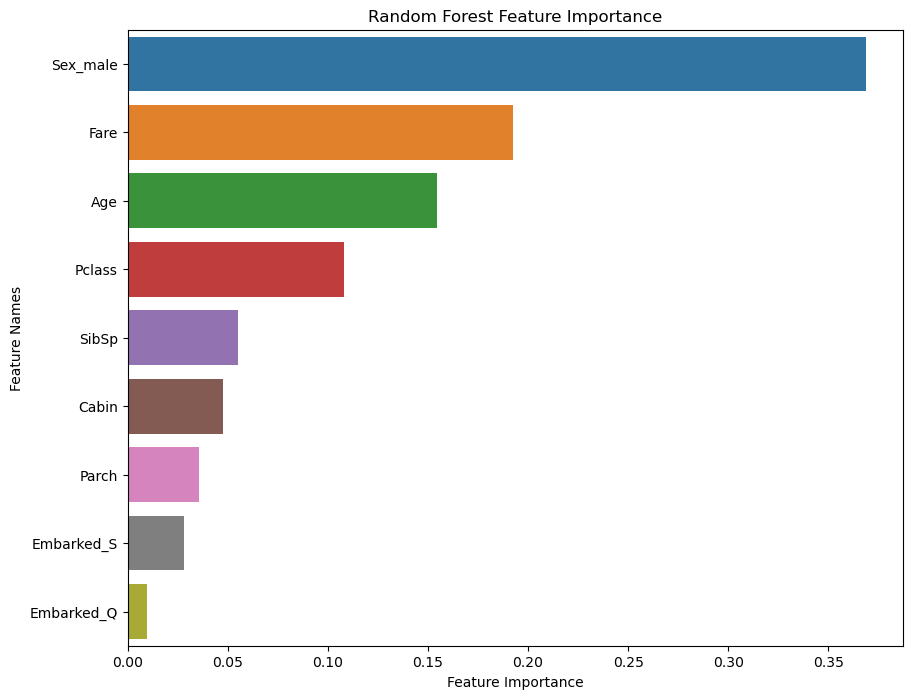

In [100]:
plot_feature_importance(gs.best_estimator_.feature_importances_,X.columns,"Random Forest")

## Can we visualize one of these trees?
---

In [101]:
from sklearn.tree import plot_tree

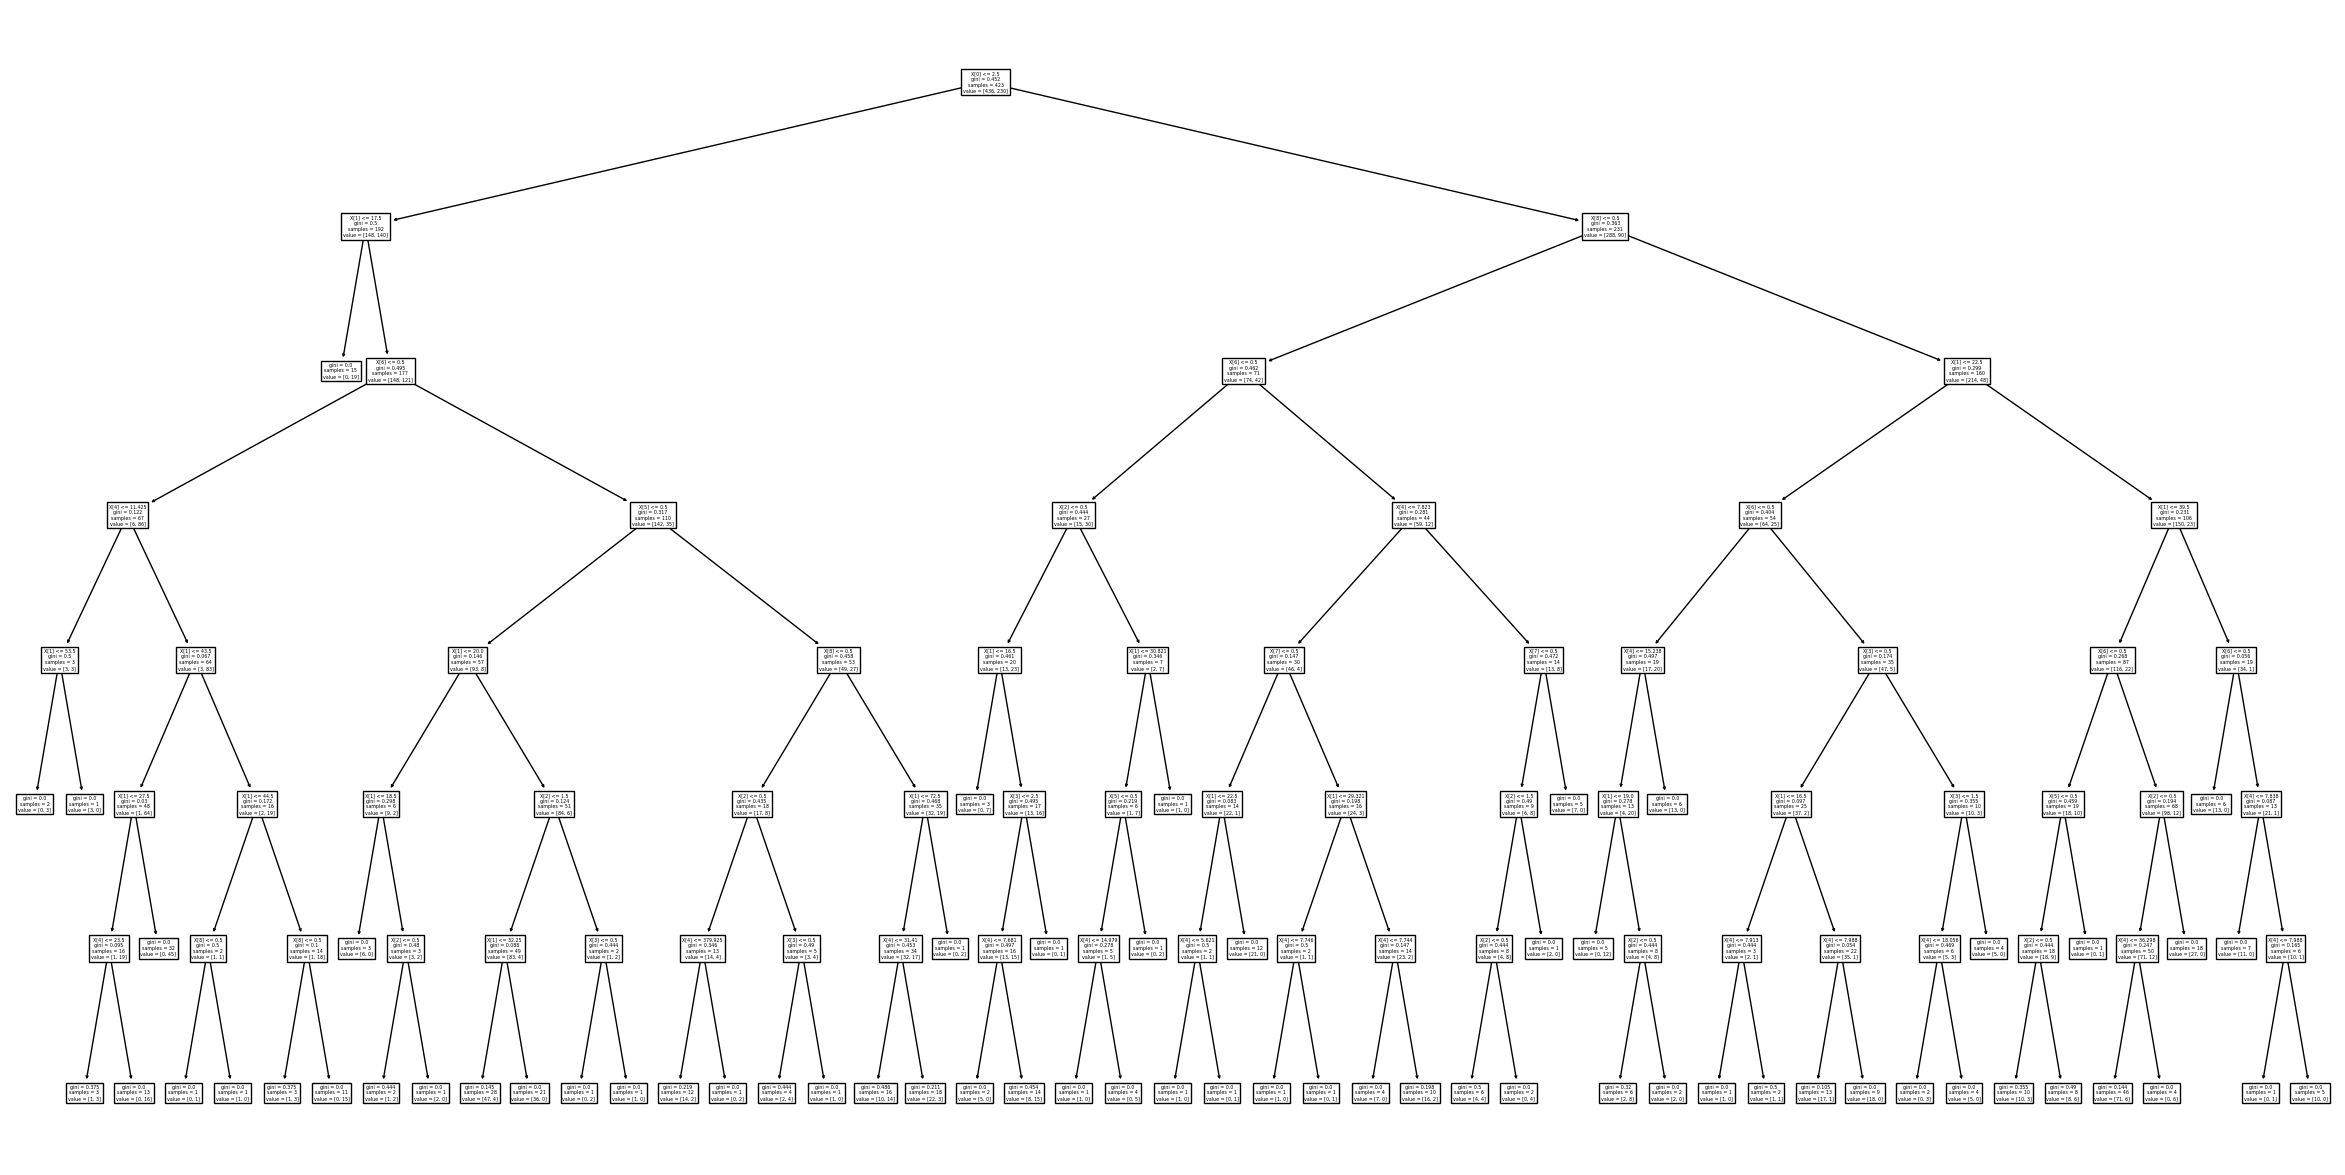

In [102]:
plt.figure(figsize = (30,15))
plot_tree(gs.best_estimator_.estimators_[0]);

## Kaggle Submission
---

Now that we've evaluated our model, let's submit our predictions to [Kaggle](https://www.kaggle.com/competitions/titanic/overview).

In [196]:
pred = gs.predict(test[features])

In [197]:
test['Survived'] = pred

In [198]:
test[['PassengerId', 'Survived']]

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0
...,...,...
413,1305,0
414,1306,1
415,1307,0
416,1308,0
